# Tutorial 1f: Paraxial Gaussian Beams and Resonators

*Last verified against the Optiland development version (after v0.6.3).*

Ray tracing tells you where light goes. It cannot tell you how large a laser
beam is at its focus, where its waist sits, or which beam a resonator supports. For a
well-behaved laser beam all of that follows from one complex number, the **beam
parameter** $q$, and the same ray-transfer (ABCD) matrices that Optiland already
computes for every system.

This tutorial introduces two tools:

- `GaussianBeam` (in `optiland.physical_optics`): a paraxial, rotationally symmetric
  Gaussian beam at one plane, described by its beam parameter $q$.
- `GaussianBeamAnalysis` (in `optiland.analysis`): carries a beam surface by surface
  through any `Optic` that the first-order engine supports, mirrors and folds included.

You will focus a laser with a real lens, design a mode-matching telescope and find the
eigenmode of a resonator. Then you will use the arm cavity of ETpathfinder to reproduce
Figure 6.5 of the
[ETpathfinder Design Report](https://www.etpathfinder.eu/wp-content/uploads/2020/03/ETpathfinder-Design-Report.pdf)
and go a little further. If you have worked through
[Tutorial 1a](Tutorial_1a_Optiland_for_Beginners.ipynb) and
[Tutorial 1b](Tutorial_1b_Lens_Properties_and_Prescription.ipynb), you have everything you
need.

**Conventions.** Lengths are in millimeters and wavelengths in micrometers, as everywhere
in Optiland. Beam radii $w$ are 1/e² intensity radii. The beam parameter is
$q = (z - z_w) + i z_R$, where $z - z_w$ is the signed distance from the waist (negative
before it) and $z_R = \pi n w_0^2 / \lambda_0$ is the Rayleigh range in a medium of
index $n$.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq, minimize

import optiland.backend as be
from optiland.analysis import GaussianBeamAnalysis
from optiland.materials import IdealMaterial
from optiland.optic import Optic
from optiland.physical_optics import GaussianBeam

## 1. A Gaussian beam in free space

`GaussianBeam.from_waist` builds a beam from its waist radius and the signed distance
from the current plane to the waist (positive when the waist lies downstream).
Everything else, from the beam radius and wavefront curvature to the divergence and the
Gouy phase, is derived from $q$. Here is a Nd:YAG beam with a 0.5 mm waist at the
starting plane, followed through free space:

In [2]:
beam = GaussianBeam.from_waist(0.5, 0.0, wavelength=1.064)  # 0.5 mm waist here
z_r = float(beam.rayleigh_range)
print(beam)
print(f"Rayleigh range  {z_r:.1f} mm")
print(f"divergence      {1e3 * float(beam.divergence):.3f} mrad (far-field half-angle)")
print()
for z in (0.0, 250.0, z_r, 3 * z_r):
    b = beam.propagate(z)
    curvature = float(b.curvature)  # 1/R, zero at the waist
    radius = "inf" if curvature == 0 else f"{1 / curvature:.1f}"
    gouy = math.degrees(float(beam.gouy_phase(z)))
    print(
        f"z = {z:7.1f} mm   w = {float(b.beam_radius):.4f} mm   "
        f"R = {radius:>7} mm   Gouy phase = {gouy:5.2f}°"
    )

GaussianBeam(w=0.5 mm, w0=0.5 mm, waist at +0 mm, wavelength=1.064 µm, m2=1.0)
Rayleigh range  738.2 mm
divergence      0.677 mrad (far-field half-angle)

z =     0.0 mm   w = 0.5000 mm   R =     inf mm   Gouy phase =  0.00°
z =   250.0 mm   w = 0.5279 mm   R =  2429.5 mm   Gouy phase = 18.71°
z =   738.2 mm   w = 0.7071 mm   R =  1476.3 mm   Gouy phase = 45.00°
z =  2214.5 mm   w = 1.5811 mm   R =  2460.5 mm   Gouy phase = 71.57°


At one Rayleigh range the beam is $\sqrt{2}$ times wider than at the waist, its
wavefront radius is at its smallest ($2 z_R$) and it has picked up 45° of Gouy phase.
`curvature` returns $1/R$ rather than $R$, so it stays finite (zero) at the waist, which
keeps gradients well-behaved on the PyTorch backend.

## 2. Focusing a laser with a real lens

`GaussianBeamAnalysis(optic, beam)` takes the beam just before surface 1 (its waist
position is measured from the vertex of surface 1) and applies each surface's
ray-transfer matrix in turn, recording the beam before and after every surface. Here a
collimated 1 mm beam is focused by a plano-convex N-BK7 singlet whose image plane sits
at the paraxial focus:

In [3]:
singlet = Optic(name="Plano-convex singlet")
singlet.surfaces.add(index=0, radius=be.inf, thickness=be.inf)
singlet.surfaces.add(index=1, radius=51.68, thickness=5.0, material="N-BK7", is_stop=True)
singlet.surfaces.add(index=2, radius=be.inf, thickness=100.0)
singlet.surfaces.add(index=3)
singlet.set_aperture(aperture_type="EPD", value=10.0)
singlet.fields.set_type("angle")
singlet.fields.add(y=0.0)
singlet.wavelengths.add(value=1.064, is_primary=True)
singlet.updater.image_solve()  # put the image plane at the paraxial focus

collimated = GaussianBeam.from_waist(1.0, 0.0, wavelength=1.064)  # waist on the lens
focusing = GaussianBeamAnalysis(singlet, collimated)

at_image = focusing.beam_at(-1, "before")
f2 = float(singlet.paraxial.f2())
print(f"effective focal length       {f2:.3f} mm")
print(f"waist radius at the focus    {1e3 * float(at_image.waist_radius):.2f} µm")
print(f"thin-lens estimate λf/(πw)   {1.064 * f2 / (math.pi * 1.0):.2f} µm")
print(
    "waist relative to the paraxial image plane "
    f"{1e3 * float(at_image.waist_position):+.1f} µm"
)

effective focal length       102.006 mm
waist radius at the focus    34.53 µm
thin-lens estimate λf/(πw)   34.55 µm
waist relative to the paraxial image plane -121.6 µm


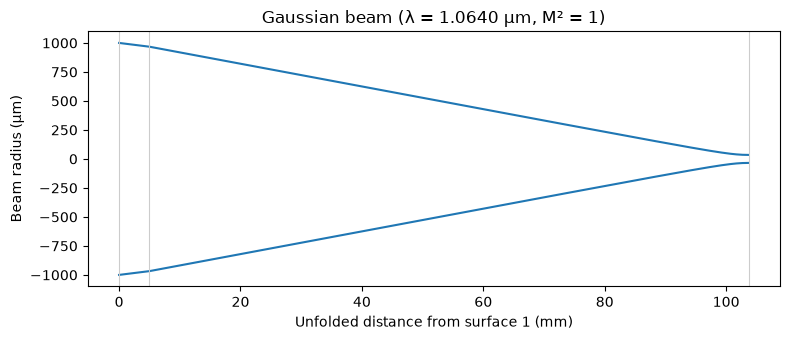

In [4]:
focusing.view(figsize=(8, 3.5));

`view()` draws the beam envelope $\pm w$ along the unfolded optical axis, with a
gray line at each surface. The focal waist agrees with the thin-lens estimate
$\lambda f / (\pi w)$, and it sits a little *before* the paraxial image plane: a
Gaussian beam with a finite Rayleigh range focuses slightly short of the geometric focus
(Self, 1983).

## 3. Mode matching into a cavity

A laser rarely has the beam that a cavity, a fiber or an amplifier wants.
`GaussianBeam.overlap` returns the fraction of power that one TEM00 beam couples into
another at the same plane,
$\eta = 4\,\mathrm{Im}\,q_1\,\mathrm{Im}\,q_2 / |q_1^* - q_2|^2$.

Here a laser with a 0.5 mm waist 200 mm before the first lens has to be matched into a
cavity mode with a 0.15 mm waist at the image plane of a telescope made of two N-BK7
plano-convex lenses (f = 200 mm and 100 mm). The lens separation and the distance to
the cavity are the two free parameters.

In [5]:
WAVELENGTH = 1.064  # µm


def telescope(separation=300.0, back_distance=150.0):
    """Two N-BK7 plano-convex singlets, f = 200 mm and f = 100 mm at 1064 nm."""
    lens = Optic(name="Mode-matching telescope")
    lens.surfaces.add(index=0, radius=be.inf, thickness=be.inf)
    lens.surfaces.add(index=1, radius=101.3, thickness=4.0, material="N-BK7", is_stop=True)
    lens.surfaces.add(index=2, radius=be.inf, thickness=separation)
    lens.surfaces.add(index=3, radius=50.66, thickness=4.0, material="N-BK7")
    lens.surfaces.add(index=4, radius=be.inf, thickness=back_distance)
    lens.surfaces.add(index=5)  # plane of the cavity waist
    lens.set_aperture(aperture_type="EPD", value=10.0)
    lens.fields.set_type("angle")
    lens.fields.add(y=0.0)
    lens.wavelengths.add(value=WAVELENGTH, is_primary=True)
    return lens


laser = GaussianBeam.from_waist(0.5, -200.0, wavelength=WAVELENGTH)
cavity_mode = GaussianBeam.from_waist(0.15, 0.0, wavelength=WAVELENGTH)


def coupling(separation, back_distance):
    """Power coupled from the laser into the cavity mode."""
    analysis = GaussianBeamAnalysis(telescope(separation, back_distance), laser)
    return float(analysis.beam_at(-1, "before").overlap(cavity_mode))


print(f"starting telescope: η = {coupling(300.0, 150.0):.4f}")

best = minimize(
    lambda x: 1.0 - coupling(*x),
    x0=[300.0, 150.0],
    method="Nelder-Mead",
    options={"xatol": 1e-4, "fatol": 1e-12},
)
separation, back_distance = best.x
print(
    f"optimized: separation {separation:.2f} mm, distance to the cavity "
    f"{back_distance:.2f} mm, η = {1 - best.fun:.6f}"
)
for error in (1.0, 5.0, 10.0):
    low = coupling(separation - error, back_distance)
    high = coupling(separation + error, back_distance)
    print(f"separation error ±{error:>4.1f} mm: η = {low:.4f} / {high:.4f}")

starting telescope: η = 0.7566
optimized: separation 369.52 mm, distance to the cavity 185.94 mm, η = 1.000000
separation error ± 1.0 mm: η = 0.9999 / 0.9999
separation error ± 5.0 mm: η = 0.9979 / 0.9979
separation error ±10.0 mm: η = 0.9915 / 0.9915


Two free distances are enough to match both the size and the position of the
waist, so the optimizer reaches $\eta = 1$. The last lines show how forgiving the result
is to an error in the lens separation.

## 4. A resonator: the ETpathfinder arm cavity

A stable optical resonator supports exactly one Gaussian beam that reproduces itself
after a round trip. `GaussianBeam.from_round_trip` solves $q = (Aq + B)/(Cq + D)$ for the
round-trip matrix of a cavity.

ETpathfinder's arm cavities (Section 6.4 of the design report) have two silicon test
masses whose mirror surfaces are $L$ = 9.22 m apart, both with a 14.5 m radius of
curvature (RoC), at 1550 nm. Model the arm as an `Optic`: surface 1 is a plane at the
input test mass (ITM) heading towards the end test mass (ETM), and surfaces 2 and 3 are
the two mirrors, so `ray_transfer_matrix(1, 3)` is the round trip from the ITM back to
itself. The ETM faces a beam travelling in +z, so its radius is negative; after the
reflection the beam travels in −z, and the ITM's radius is positive.

In [6]:
L_ARM = 9220.0   # mm, ITM to ETM
ROC = 14500.0    # mm, radius of curvature of both test masses
LAMBDA = 1.55    # µm


def arm_cavity(roc_itm=ROC, roc_etm=ROC, length=L_ARM, wavelength=LAMBDA):
    """A two-mirror linear cavity, starting at the ITM and heading to the ETM."""
    arm = Optic(name="ETpathfinder arm cavity")
    arm.surfaces.add(index=0, thickness=be.inf)
    arm.surfaces.add(index=1, thickness=length, is_stop=True)  # plane at the ITM
    arm.surfaces.add(index=2, radius=-roc_etm, material="mirror", thickness=-length)
    arm.surfaces.add(index=3, radius=roc_itm, material="mirror", thickness=0.0)
    arm.surfaces.add(index=4)
    arm.set_aperture(aperture_type="EPD", value=10.0)
    arm.fields.set_type("angle")
    arm.fields.add(y=0.0)
    arm.wavelengths.add(value=wavelength, is_primary=True)
    return arm


def eigenmode(arm, wavelength=LAMBDA):
    """The beam that reproduces itself after one round trip, at the ITM."""
    round_trip = arm.paraxial.ray_transfer_matrix(1, 3, wavelength)
    return GaussianBeam.from_round_trip(round_trip, wavelength=wavelength)


arm = arm_cavity()
mode = eigenmode(arm)
round_trip = GaussianBeamAnalysis(arm, mode)

print("eigenmode at the ITM:      ", mode)
print("after one round trip:      ", round_trip.beam_at(3, "after"))
print(
    f"beam radius on the ETM:     {float(round_trip.beam_at(2, 'before').beam_radius):.4f} mm"
)

eigenmode at the ITM:       GaussianBeam(w=2.21004 mm, w0=1.82522 mm, waist at +4610 mm, wavelength=1.55 µm, m2=1.0)
after one round trip:       GaussianBeam(w=2.21004 mm, w0=1.82522 mm, waist at +4610 mm, wavelength=1.55 µm, m2=1.0)
beam radius on the ETM:     2.2100 mm


The design report quotes a waist of 1.825 mm and a beam radius of 2.21 mm on the
test masses for this cavity, and Optiland reproduces both. The waist sits halfway
between the mirrors (+4610 mm from the ITM), as it must in a symmetric cavity, and the
beam comes back unchanged after the round trip.

## 5. Reproducing Figure 6.5 of the ETpathfinder Design Report

Figure 6.5 of the report shows the arm-cavity waist and the beam radius on the test
masses as the common RoC of the ITM and ETM changes, at 1550 nm. Each point below is one
call to `from_round_trip` on a new cavity.

A symmetric two-mirror cavity also has closed-form answers,
$w_0^2 = \frac{\lambda}{2\pi}\sqrt{L(2R - L)}$ and
$w_\mathrm{mirror}^2 = \frac{\lambda L}{\pi}\frac{1}{\sqrt{1 - g^2}}$ with
$g = 1 - L/R$. They are drawn as dotted lines on top, as an independent check. The cavity
is only stable for $R > L/2$ = 4.61 m, which is why the curves stop near 5 m.

largest difference from the closed form: 7.3e-12 mm


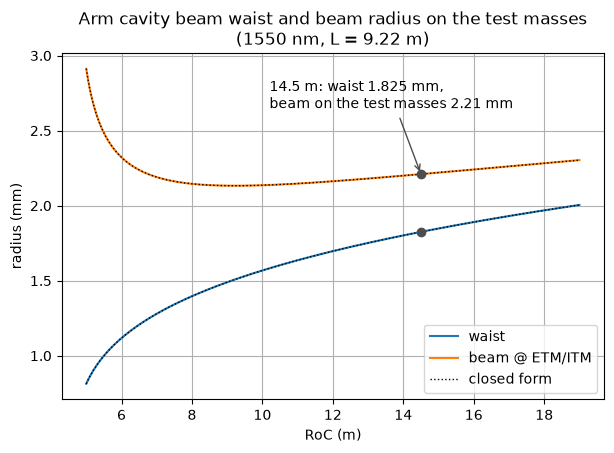

In [7]:
rocs = np.linspace(5.0, 19.0, 281) * 1e3  # mm
waist, spot = [], []
for roc in rocs:
    m = eigenmode(arm_cavity(roc, roc))
    waist.append(float(m.waist_radius))
    spot.append(float(m.beam_radius))  # the eigenmode is evaluated on the ITM
waist, spot = np.array(waist), np.array(spot)

lam = LAMBDA * 1e-3  # mm
g = 1 - L_ARM / rocs
waist_closed = np.sqrt(lam / (2 * np.pi) * np.sqrt(L_ARM * (2 * rocs - L_ARM)))
spot_closed = np.sqrt(lam * L_ARM / (np.pi * np.sqrt(1 - g**2)))
difference = max(np.abs(waist - waist_closed).max(), np.abs(spot - spot_closed).max())
print(f"largest difference from the closed form: {difference:.1e} mm")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(rocs / 1e3, waist, label="waist")
ax.plot(rocs / 1e3, spot, label="beam @ ETM/ITM")
ax.plot(rocs / 1e3, waist_closed, "k:", linewidth=1, label="closed form")
ax.plot(rocs / 1e3, spot_closed, "k:", linewidth=1)
ax.plot([14.5, 14.5], [float(mode.waist_radius), float(mode.beam_radius)], "o", color="0.3")
ax.annotate(
    f"14.5 m: waist {float(mode.waist_radius):.3f} mm,\n"
    f"beam on the test masses {float(mode.beam_radius):.2f} mm",
    xy=(14.5, float(mode.beam_radius)),
    xytext=(10.2, 2.65),
    arrowprops={"arrowstyle": "->", "color": "0.3"},
)
ax.set_xlabel("RoC (m)")
ax.set_ylabel("radius (mm)")
ax.set_title("Arm cavity beam waist and beam radius on the test masses\n"
             "(1550 nm, L = 9.22 m)")
ax.grid(True)
ax.legend(loc="lower right")
plt.show()

The beam on the mirrors is smallest at the confocal point $R = L$ (about 9.2 m)
and grows quickly towards the edge of stability at $R = L/2$, where the waist shrinks to
zero. Optiland's eigenmodes lie on the closed-form curves everywhere.

Why choose 14.5 m rather than the confocal point? The next section looks at the
higher-order modes.

## 6. Higher-order modes and the choice of RoC

A Hermite-Gauss mode of order $N = m + n$ picks up $N$ times more Gouy phase per round
trip than TEM00, so it resonates at a round-trip phase offset of $N\psi_\mathrm{rt}$. When
that offset comes close to a multiple of $2\pi$, the mode resonates together with TEM00,
and any misalignment or mirror figure error that scatters light into it is amplified.
Section 6.4 of the report chose the RoC to keep the low orders away from that, using the
Finesse simulation package (its Figure 6.4).

`GaussianBeamAnalysis` accumulates the Gouy phase along the legs of the round trip, so
$\psi_\mathrm{rt}$ comes straight out of it. For a cavity of finesse $\mathcal{F}$, the power
build-up of order $N$ relative to TEM00 on resonance is the Airy function
$1/[1 + (2\mathcal{F}/\pi)^2 \sin^2(N\psi_\mathrm{rt}/2)]$. The design report does not
state the finesse, so this plot uses $\mathcal{F} \approx 2050$ from Utina et al.
(2022). It shows the same physics as Figure 6.4 but is not a reproduction of it.

The resonances are only about 2 mm wide in RoC, so $\psi_\mathrm{rt}$ is computed with
Optiland on a 20 mm grid and interpolated linearly onto a 0.2 mm grid. The interpolation
error is a hundred times smaller than the resonance width.

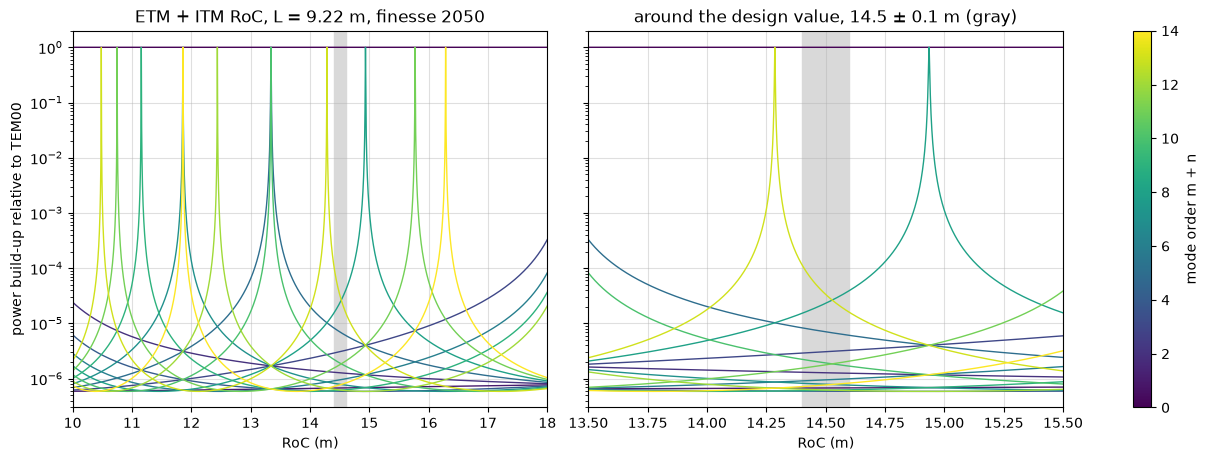

In [8]:
FINESSE = 2050  # Utina et al. 2022; the design report does not state it

coarse = np.linspace(10.0, 18.0, 401) * 1e3  # mm
gouy_rt = []
for roc in coarse:
    cavity = arm_cavity(roc, roc)
    trip = GaussianBeamAnalysis(cavity, eigenmode(cavity))
    gouy_rt.append(float(trip.data["gouy_phase"][-1]))  # Gouy phase over the round trip
gouy_rt = np.array(gouy_rt)

fine = np.linspace(10.0, 18.0, 40001) * 1e3
psi = np.interp(fine, coarse, gouy_rt)
airy = (2 * FINESSE / np.pi) ** 2


def buildup(order, psi):
    """Power build-up of mode order N relative to TEM00 on resonance."""
    return 1.0 / (1.0 + airy * np.sin(order * psi / 2) ** 2)


cmap = plt.get_cmap("viridis")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, layout="constrained")
for ax, (low, high) in zip(axes, [(10.0, 18.0), (13.5, 15.5)]):
    keep = (fine >= low * 1e3) & (fine <= high * 1e3)
    for order in range(15):
        ax.plot(fine[keep] / 1e3, buildup(order, psi[keep]), color=cmap(order / 14),
                linewidth=1)
    ax.axvspan(14.4, 14.6, color="0.85", zorder=0)  # polishing tolerance ±0.1 m
    ax.set_xlim(low, high)
    ax.set_yscale("log")
    ax.set_ylim(3e-7, 2)
    ax.set_xlabel("RoC (m)")
    ax.grid(True, alpha=0.4)
axes[0].set_ylabel("power build-up relative to TEM00")
axes[0].set_title("ETM + ITM RoC, L = 9.22 m, finesse 2050")
axes[1].set_title("around the design value, 14.5 ± 0.1 m (gray)")
fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 14)), ax=axes,
             label="mode order m + n")
plt.show()

In [9]:
psi_design = float(round_trip.data["gouy_phase"][-1])
fsr = 299_792_458.0 / (2 * L_ARM * 1e-3)  # free spectral range in Hz
linewidth = 2 * np.pi / FINESSE           # in round-trip phase
print(
    f"round-trip Gouy phase {math.degrees(psi_design):.2f}°, transverse mode spacing "
    f"{fsr * psi_design / (2 * np.pi) / 1e6:.4f} MHz"
)
print("closest higher-order modes at 14.5 m, up to order 20:")
offsets = []
for order in range(1, 21):
    offset = (order * psi_design + np.pi) % (2 * np.pi) - np.pi
    offsets.append((abs(offset), order, offset))
for _, order, offset in sorted(offsets)[:3]:
    print(
        f"  order {order:2d}: {math.degrees(offset):+6.2f}° from TEM00, "
        f"{abs(offset) / linewidth:4.0f} linewidths, "
        f"{fsr * abs(offset) / (2 * np.pi) / 1e6:.3f} MHz"
    )

round-trip Gouy phase 137.29°, transverse mode spacing 6.2001 MHz
closest higher-order modes at 14.5 m, up to order 20:
  order 13: -15.22° from TEM00,   87 linewidths, 0.687 MHz
  order  8: +18.33° from TEM00,  104 linewidths, 0.828 MHz
  order  5: -33.55° from TEM00,  191 linewidths, 1.515 MHz


At 14.5 m the closest mode up to order 20 is order 13, 87 linewidths away from
TEM00. In the zoomed panel, order 13 resonates at 14.29 m and order 8 at 14.94 m, on
either side of the design value, and the ±0.1 m polishing tolerance (gray band) stays
clear of both. That is the conclusion the report draws from its Figure 6.4. At the
confocal point (9.22 m, just left of the plotted range) every even order resonates
together with TEM00, which is why a confocal arm is avoided.

## 7. Leaving the cavity through a silicon test mass

The report notes that silicon's high refractive index (about 3.45 at 1550 nm) makes the
test masses "surprisingly strong diverging lenses", so their anti-reflective (AR) side
has to be curved too. The beam that leaves the arm through the ITM is easy to follow
with the same analysis. Start from the cavity waist, $L/2$ before the ITM's reflective
(HR) face, then go through 80 mm of silicon (`IdealMaterial(n=3.45)`) and the AR
surface. The beam travels in +z, so a convex AR surface has a negative radius.

Compare three AR surfaces: a flat one, the convex 9.0 m radius of Utina et al. (2022),
and the radius that collimates the beam exactly (waist on the AR surface), found with
`scipy.optimize.brentq`.

flat AR surface                        waist 0.864 mm at -3.584 m
convex AR, R = 9.0 m                   waist 2.095 mm at +3.148 m
convex AR, R = 10.34 m (collimating)   waist 2.222 mm at +0.000 m


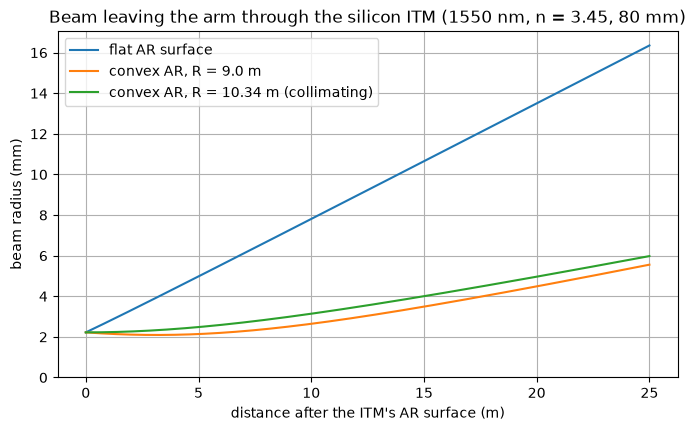

In [10]:
N_SI = 3.45       # silicon at 1550 nm, as in the design report
THICKNESS = 80.0  # mm


def itm_exit(ar_radius, n=N_SI):
    """The beam just after the ITM's AR surface, leaving the arm cavity."""
    itm = Optic(name="ETpathfinder ITM, cavity side first")
    itm.surfaces.add(index=0, thickness=be.inf)
    itm.surfaces.add(index=1, radius=-ROC, thickness=THICKNESS,  # HR, concave to the cavity
                     material=IdealMaterial(n=n), is_stop=True)
    itm.surfaces.add(index=2, radius=ar_radius, thickness=1000.0)  # AR surface
    itm.surfaces.add(index=3)
    itm.set_aperture(aperture_type="EPD", value=10.0)
    itm.fields.set_type("angle")
    itm.fields.add(y=0.0)
    itm.wavelengths.add(value=LAMBDA, is_primary=True)
    leaving = GaussianBeam.from_waist(mode.waist_radius, -L_ARM / 2, wavelength=LAMBDA)
    return GaussianBeamAnalysis(itm, leaving).beam_at(2, "after")


collimating = brentq(lambda r: float(itm_exit(r).waist_position), -20000.0, -6000.0,
                     xtol=1e-6)
ar_options = {
    "flat AR surface": be.inf,
    "convex AR, R = 9.0 m": -9000.0,
    f"convex AR, R = {abs(collimating) / 1e3:.2f} m (collimating)": collimating,
}

distance = np.linspace(0.0, 25000.0, 501)  # mm after the AR surface
fig, ax = plt.subplots(figsize=(8, 4.5))
for label, ar_radius in ar_options.items():
    out = itm_exit(ar_radius)
    radius = be.to_numpy(out.propagate(distance).beam_radius)
    ax.plot(distance / 1e3, radius, label=label)
    waist_at = round(float(out.waist_position) / 1e3, 3) + 0.0  # avoid printing -0.000
    print(f"{label:38s} waist {float(out.waist_radius):.3f} mm at {waist_at:+.3f} m")
ax.set_xlabel("distance after the ITM's AR surface (m)")
ax.set_ylabel("beam radius (mm)")
ax.set_ylim(0, None)
ax.set_title("Beam leaving the arm through the silicon ITM (1550 nm, n = 3.45, 80 mm)")
ax.grid(True)
ax.legend()
plt.show()

With a flat AR side the test mass is a negative lens of focal length about
$-R/(n - 1) \approx -5.9$ m, and the beam leaves strongly diverging. A convex AR surface
with a radius close to that of the HR side compensates it. The exactly collimating radius
depends on the index: about 10.34 m at the report's $n$ = 3.45, against 10.40 m at the
paper's 3.5, so the substrate index matters at the 10 cm level.

The same lens matters for the input optics. The beam to inject is the exit beam run
backwards. A beam matched to the bare cavity mode, as if the substrate were not there,
couples noticeably worse:

In [11]:
def injected(beam, ar_radius, n=N_SI):
    """A beam sent into the arm through the ITM, just inside the cavity."""
    itm = Optic(name="ETpathfinder ITM, outside first")
    itm.surfaces.add(index=0, thickness=be.inf)
    itm.surfaces.add(index=1, radius=-ar_radius, thickness=THICKNESS,  # AR surface
                     material=IdealMaterial(n=n), is_stop=True)
    itm.surfaces.add(index=2, radius=ROC, thickness=100.0)  # HR, concave to the cavity
    itm.surfaces.add(index=3)
    itm.set_aperture(aperture_type="EPD", value=10.0)
    itm.fields.set_type("angle")
    itm.fields.add(y=0.0)
    itm.wavelengths.add(value=LAMBDA, is_primary=True)
    return GaussianBeamAnalysis(itm, beam).beam_at(2, "after")


cavity_mode_at_itm = GaussianBeam.from_waist(mode.waist_radius, L_ARM / 2,
                                             wavelength=LAMBDA)
exit_beam = itm_exit(collimating)
reversed_exit = GaussianBeam.from_waist(exit_beam.waist_radius,
                                        -exit_beam.waist_position, wavelength=LAMBDA)
bare_match = GaussianBeam.from_waist(mode.waist_radius, L_ARM / 2 + THICKNESS,
                                     wavelength=LAMBDA)
for label, beam in (("exit beam run backwards", reversed_exit),
                    ("matched to the bare cavity mode", bare_match)):
    eta = injected(beam, collimating).overlap(cavity_mode_at_itm)
    print(f"{label:32s} mode matching η = {float(eta):.4f}")

exit beam run backwards          mode matching η = 1.0000
matched to the bare cavity mode  mode matching η = 0.8924


## Summary

- `GaussianBeam.from_waist` creates a beam. `beam_radius`, `waist_radius`,
  `waist_position`, `curvature`, `divergence` and `gouy_phase` describe it, and
  `propagate` moves it through free space.
- `GaussianBeamAnalysis(optic, beam)` carries it through a system. Use `beam_at` for the
  beam at a surface, `data["gouy_phase"]` for the accumulated Gouy phase and `view()` for
  the envelope.
- `overlap` gives the mode-matching efficiency between two TEM00 beams. Because it is a
  plain function of the system, any optimizer can maximize it.
- `from_round_trip` gives the eigenmode of a stable resonator from its round-trip
  matrix. With it you reproduced Figure 6.5 of the ETpathfinder Design Report, examined
  the higher-order-mode spectrum behind the choice of RoC, and followed the beam out
  through the silicon test mass.

The model is paraxial and rotationally symmetric. A powered mirror used at oblique
incidence emits a `ParaxialDomainWarning`, because its astigmatism is ignored, and
systems outside the first-order engine's domain raise an error, exactly as in the rest of
the paraxial API. Everything above also runs on the PyTorch backend, with gradients with
respect to radii and thicknesses (see
[Tutorial 7a](Tutorial_7a_Differentiable_Ray_Tracing_Hello_World.ipynb)).

## References

1. ETpathfinder Team, *ETpathfinder Design Report* (2020), Section 6.4, Figures 6.4 and
   6.5. https://www.etpathfinder.eu/wp-content/uploads/2020/03/ETpathfinder-Design-Report.pdf
2. A. Utina et al., "ETpathfinder: a cryogenic testbed for interferometric
   gravitational-wave detectors", *Class. Quantum Grav.* **39**, 215008 (2022).
3. H. Kogelnik and T. Li, "Laser beams and resonators", *Appl. Opt.* **5**, 1550 (1966).
4. S. A. Self, "Focusing of spherical Gaussian beams", *Appl. Opt.* **22**, 658 (1983).